# MRI Math Concepts — cheat sheet

**Part:** Reference · **Reading time:** ~15 min (look-up sheet) · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb) · [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) · [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) · [RM4](../refreshers/RM4_Fourier_Properties.ipynb) · [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) · [RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

All the mathematics used in this series on a few pages: formulas with one-line explanations, the
standard functions, the Fourier toolbox, and two worked MRI examples (k-space truncation and PSF analysis).
This page is for **looking things up**; each section links to the refresher notebook that explains the
topic slowly, with demos.

| If you need… | read |
|---|---|
| solving $dM/dt=\dots$ (decay, recovery, rotation, steady states, numerical stepping) | [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb) |
| complex numbers, phasors, $e^{-i\omega t}$, rotation matrices, cross product | [RM2 Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| continuous FT vs FFT, units, `fftshift` | [RM3 Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| shift, scaling, convolution, symmetry, Parseval | [RM4 Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb) |
| rect/sinc, comb, sampling, aliasing, ringing, windows | [RM5 Fourier pairs and sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| 2D k-space intuition | [RM6 2D Fourier and images](../refreshers/RM6_2D_Fourier_and_Images.ipynb) |

## Learning goals

1. Find, and correctly apply, the formula you need for complex numbers, ODE solutions, special functions, convolution and Fourier transforms.
2. Use the Fourier identities and pairs to predict the effect of k-space truncation (ringing) and of any k-space weighting (PSF).
3. Relate the DFT/FFT used in code to the continuous FT used in the theory.

## Symbols used on this page

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $i=\sqrt{-1}$ | imaginary unit ($j$ in engineering, `1j` in Python) | – | |
| $c=a+ib=Ae^{i\phi}$ | complex number; real part $a$, imaginary part $b$, magnitude $A$, phase $\phi$ | –, rad | |
| $t$, $\tau$ | time; $\tau$ = dummy integration variable (as everywhere in the series) | s | |
| $y_0$, $y_{eq}$, $T_c$ | initial value, equilibrium value, time constant of a generic first-order ODE | –, –, s | becomes $T_1$ or $T_2$ |
| $\omega$, $f$ | angular / ordinary frequency, $\omega=2\pi f$ | rad/s, Hz | |
| $\vec M$, $M_{xy}=M_x+iM_y$, $M_0$ | magnetization, transverse magnetization, equilibrium value | normalized ($M_0=1$) | |
| $\vec B$, $\gamma$ | magnetic field, gyromagnetic ratio | T, rad s⁻¹ T⁻¹ | |
| $T_1$, $T_2$ | relaxation **time constants** | s | |
| $A$ (matrix), $\vec b$ | system matrix and source of $d\vec M/dt=A\vec M+\vec b$ | s⁻¹ | (not the magnitude $A$ above — context) |
| $x$, $k_x$ (or $k$) | position, spatial frequency | m, m⁻¹ | |
| $\vec x$ / $\vec r$, $\vec k$ | position and k-space vectors | m, m⁻¹ | |
| $f(x)$, $F(k_x)$; $g$, $G$ | functions and their Fourier transforms | | $G$ here is not a gradient |
| $a$ (in identities) | a constant (shift, scale) | | |
| $\delta(x)$ | Dirac delta (impulse) | m⁻¹ | not the resolution $\delta$ |
| $\mathrm{III}(x)$ (also Ш) | Dirac comb / impulse train / sampling function | – | |
| $\mathrm{rect},\ \mathrm{sinc},\ \mathrm{tri},\ \mathrm{jinc}$ | standard functions (defined below) | – | |
| $*$ | convolution; as superscript $c^*$: complex conjugate | | |
| $\mathcal F\{\cdot\}$, $\mathcal F^{-1}\{\cdot\}$ | Fourier transform and inverse | | kernel $e^{-i2\pi k x}$ |
| $W_{kx}$, $k_{x,max}$ | width of sampled k-space ($=2k_{x,max}$) | m⁻¹ | |
| $\hat F$, $\hat f$ | sampled/truncated k-space and the resulting image | | |
| $psf(x)$, $PSF(k_x)$ | point spread function and its Fourier transform | m⁻¹, – | |
| $\mathcal H$ | the (linear) imaging system as an operator | | |
| $N$, $n$, $m$ | number of samples; sample indices | – | |
| $\Delta x$, $\Delta k$, $FOV$ | sample spacings, field of view $=1/\Delta k$ | m, m⁻¹, m | $\Delta x\Delta k=1/N$ |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Complex numbers → [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

$$c = a + ib = A\,e^{i\phi},\qquad i=\sqrt{-1},\qquad e^{i\phi}=\cos\phi+i\sin\phi,$$
$$|c|=A=\sqrt{a^2+b^2},\qquad \phi=\operatorname{atan2}(b,a)\quad(\texttt{np.angle}).$$

In words: a complex number is a 2D vector; $A$ is its length, $\phi$ its angle counter-clockwise from the real axis.

- $\phi=\tan^{-1}(b/a)$ (as often written, including in the original chapter) is only correct for $a>0$; use the two-argument arctangent.
- Product: $c_1c_2=A_1A_2e^{i(\phi_1+\phi_2)}$ (multiply lengths, add phases). Conjugate: $c^*=a-ib=Ae^{-i\phi}$; $|c|^2=cc^*$.
- MRI: $M_{xy}=M_x+iM_y$; precession $M_{xy}(t)=M_{xy}(0)e^{-i\omega t}$ is **clockwise** (left-handed); phase is the integral of frequency, $\phi(t)=\phi(0)-\int_0^t\omega(\tau)d\tau$.
- A sum of phasors with spread phases shrinks (dephasing → $T_2^*$).

**Rotations and cross product.** Right-handed rotation matrices `mt.Rx`, `mt.Ry`, `mt.Rz`; $R^{-1}=R^T$; order matters. $\vec a\times\vec b\perp\vec a,\vec b$, $|\vec a\times\vec b|=|\vec a||\vec b|\sin\angle$.
Bloch precession $d\vec M/dt=\gamma\vec M\times\vec B=(-\gamma\vec B)\times\vec M$: a left-handed rotation about $\vec B$ at rate $\gamma|\vec B|$ (`mt.bloch_rotate`).

## 2. First-order ODEs → [RM1](../refreshers/RM1_ODEs_for_MRI.ipynb)

| equation | solution | MRI example |
|---|---|---|
| $\dfrac{dy}{dt}=-\dfrac{y}{T_c}$ | $y=y_0e^{-t/T_c}$ | $\lvert M_{xy}\rvert$ decay with $T_2$ |
| $\dfrac{dy}{dt}=\dfrac{y_{eq}-y}{T_c}$ | $y=y_{eq}+(y_0-y_{eq})e^{-t/T_c}$ | $M_z$ recovery with $T_1$ towards $M_0$ |
| $\dfrac{dy}{dt}+ay=c(t)$ | $y=y_0e^{-at}+\displaystyle\int_0^te^{-a(t-\tau)}c(\tau)\,d\tau$ | general linear, any input |
| $\dfrac{dz}{dt}=-i\omega z$, $z=x+iy$ | $z=z_0e^{-i\omega t}$ | precession: $dM_x/dt=\omega M_y$, $dM_y/dt=-\omega M_x$ |
| $\dfrac{d\vec M}{dt}=A\vec M+\vec b$ | $\vec M=\vec M_{ss}+e^{At}(\vec M(0)-\vec M_{ss})$, $\vec M_{ss}=-A^{-1}\vec b$ | Bloch equation with constant field |

In words: **final value + (initial − final)·e^{−t/T_c}** covers every relaxation formula; a steady state is where $d\vec M/dt=0$ (or, for pulse trains, where the magnetization is the same before every pulse).
Numerically, never use forward Euler for precession (it spirals outwards); use exact rotation + exact relaxation per time step (`mt.bloch_simulate`).

## 3. The impulse (Dirac delta) function → [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

The impulse $\delta(x)$ represents an ideal point object, or one ideal sample of a continuous signal. It is the limit of ever narrower, ever taller unit-area pulses (strictly a *distribution*, not an ordinary function):

- $\delta(x)=0$ for all $x\ne0$, and it is "infinitely high" at $x=0$ in the sense that
- $\int_{-\infty}^{\infty}\delta(x)\,dx=1$ (unit area; unit of $\delta(x)$ is 1/[unit of $x$]);
- $\delta(ax)=\dfrac{1}{|a|}\delta(x)$;
- $f(x)\,\delta(x-a)=f(a)\,\delta(x-a)$, and the **sifting** property $\int f(x)\delta(x-a)\,dx=f(a)$;
- $f(x)*\delta(x)=f(x)$ and $f(x)*\delta(x-a)=f(x-a)$ (convolving with a shifted impulse shifts).

On a grid of spacing $\Delta x$, a delta is a single sample of height $1/\Delta x$.

### Impulse train (sampling function)

A train of unit impulses represents discrete sampling. It is called the **Dirac comb**, sha (Ш, written $\mathrm{III}$ in this series), impulse train or sampling function:

$$\mathrm{III}(x)=\sum_{n=-\infty}^{\infty}\delta(x-n),\qquad \sum_{n}\delta(x-n\Delta x)=\frac{1}{\Delta x}\mathrm{III}\!\left(\frac{x}{\Delta x}\right).$$

In words: spikes at every integer (or every multiple of the spacing $\Delta x$). Multiplying a function by it keeps only the samples; its FT is again a comb with the reciprocal spacing.

## 4. Other standard functions

$$\mathrm{rect}(x)=\sqcap(x)=\begin{cases}1 & |x|<1/2\\ 1/2 & |x|=1/2\\ 0 & |x|>1/2\end{cases}\qquad
\mathrm{sinc}(x)=\frac{\sin(\pi x)}{\pi x}\ (\mathrm{sinc}(0)=1)\qquad
\mathrm{tri}(x)=\max(1-|x|,0)$$
$$\text{Gaussian } e^{-\pi x^2}\qquad
\mathrm{jinc}(x)=\frac{J_1(\pi x)}{\pi x}\ (\mathrm{jinc}(0)=\tfrac12)$$

In words: rect = unit box (a slice profile, a finite sampling window); sinc = its FT, the "normalized" sinc with zeros at every non-zero integer (`np.sinc`); tri = rect ∗ rect; the Gaussian $e^{-\pi x^2}$ is its own FT;
jinc = the 2D, circularly symmetric analogue of sinc ($J_1$ = Bessel function of the first kind, order 1; definitions with other factors exist — this is the one in `mt.jinc`).

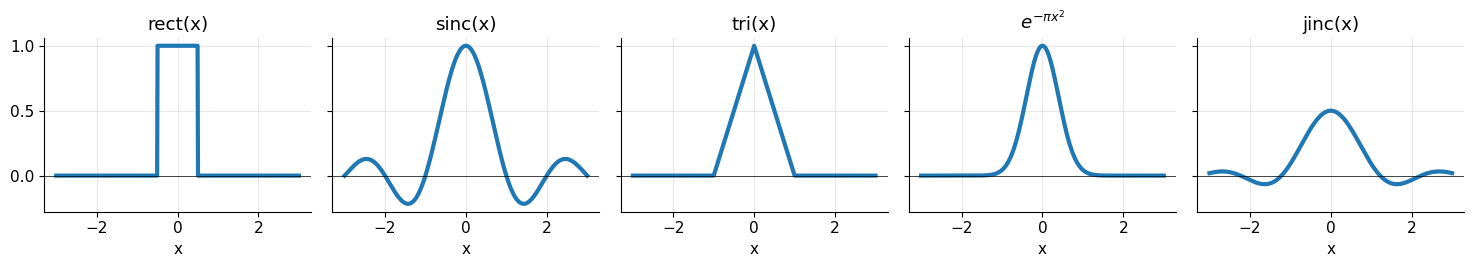

In [2]:
x = np.linspace(-3, 3, 1201)
funcs = [("rect(x)", mt.rect(x)), ("sinc(x)", np.sinc(x)), ("tri(x)", np.maximum(1 - np.abs(x), 0)),
         (r"$e^{-\pi x^2}$", np.exp(-np.pi * x**2)), ("jinc(x)", mt.jinc(x))]
fig, ax = plt.subplots(1, 5, figsize=(15, 2.8), sharey=True)
for a_, (name, f) in zip(ax, funcs):
    a_.plot(x, f, lw=3); a_.set_title(name); a_.set_xlabel("x"); a_.axhline(0, color="k", lw=0.5)
plt.tight_layout(); plt.show()

The rect has value 1/2 exactly at its edges (`mt.rect`); sinc and jinc oscillate with decaying side lobes, tri and Gaussian are non-negative.

## 5. Convolution → [RM4](../refreshers/RM4_Fourier_Properties.ipynb)

$$g(x)*h(x)=\int_{-\infty}^{\infty}g(x-\tau)\,h(\tau)\,d\tau.$$

In words: one function is reversed and slid across the other; at each shift $x$ the overlap of the two (their product, integrated) is the output. Where: $\tau$ = dummy integration variable.
Convolution is commutative ($g*h=h*g$), and convolving with $\delta$ changes nothing. The animation (from [Wikipedia](https://en.wikipedia.org/wiki/Convolution)) shows a box convolved with itself, which gives a triangle:

![Convolution of a box with itself](../images/Convolution_of_box_signal_with_itself2.gif)

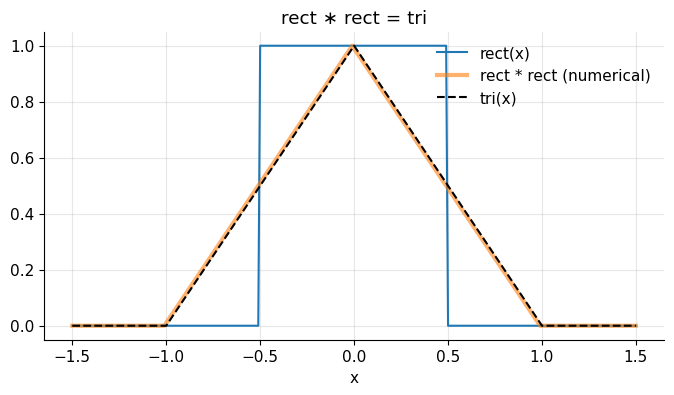

In [3]:
dxs = 0.01
xs = np.arange(-1.5, 1.5 + dxs / 2, dxs)
box = mt.rect(xs)
tri_num = np.convolve(box, box, mode="same") * dxs          # Riemann-sum convolution (dx makes it an integral)
plt.plot(xs, box, label="rect(x)"); plt.plot(xs, tri_num, lw=3, alpha=0.6, label="rect * rect (numerical)")
plt.plot(xs, np.maximum(1 - np.abs(xs), 0), "k--", label="tri(x)")
plt.xlabel("x"); plt.legend(); plt.title("rect ∗ rect = tri"); plt.show()

The numerical convolution of the box with itself is the triangle of width 2 and height 1 (= area of the box).

## 6. Fourier transforms → [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)

The Fourier transform tells which frequencies are present in a function. For a complex-valued $f(x)$:

$$\mathcal F\{f(x)\}=F(k_x)=\int_{-\infty}^{\infty}f(x)\,e^{-i2\pi k_xx}\,dx.$$

In words: $F(k_x)$ is the amount (and phase) of the wave $e^{i2\pi k_xx}$, which has $k_x$ cycles per metre, contained in $f$. Where: $x$ [m], $k_x$ [m⁻¹].

This is the **unitary, ordinary-frequency** convention (no $2\pi$ prefactors); the variable pair $(x,k_x)$ can be renamed, most commonly to time $t$ [s] and frequency $f$ [Hz].
Physics texts often use angular frequency instead, $F(\omega)=\int f(t)e^{-i\omega t}dt$ with $f(t)=\frac{1}{2\pi}\int F(\omega)e^{i\omega t}d\omega$ — formulas copied from such sources need $\omega\to2\pi f$.

**Inverse:**
$$\mathcal F^{-1}\{F(k_x)\}=f(x)=\int_{-\infty}^{\infty}F(k_x)\,e^{+i2\pi xk_x}\,dk_x.$$

**2D:**
$$F(k_x,k_y)=\iint f(x,y)\,e^{-i2\pi(k_xx+k_yy)}\,dx\,dy.$$

**N-D:**
$$F(\vec k)=\int f(\vec x)\,e^{-i2\pi\vec k\cdot\vec x}\,d\vec x.$$

In words: in more dimensions the wave becomes a plane wave $e^{i2\pi\vec k\cdot\vec x}$ — stripes perpendicular to $\vec k$ with wavelength $1/|\vec k|$ ([RM6](../refreshers/RM6_2D_Fourier_and_Images.ipynb)).

**Duality** (the forward and inverse transforms differ only by a sign):
$$\mathcal F\{f(x)\}=F(k_x)\;\Rightarrow\;\mathcal F\{F(x)\}=f(-k_x),\qquad \mathcal F\{F(-x)\}=f(k_x).$$

**Separability:** if $f(x,y)=f_x(x)f_y(y)$ then $\mathcal F\{f(x,y)\}=\mathcal F\{f_x\}(k_x)\cdot\mathcal F\{f_y\}(k_y)$. More generally, any 2D FT can be computed as 1D FTs along $x$, then along $y$.

## 7. Fourier identities and pairs → [RM4](../refreshers/RM4_Fourier_Properties.ipynb), [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

For $\mathcal F\{f(x)\}=F(k_x)$ and $\mathcal F\{g(x)\}=G(k_x)$:

| Function | Fourier transform | name / MRI meaning |
|:---|:---|:---|
| $\delta(x)$ | $1$ | a point contains all frequencies |
| $1$ | $\delta(k_x)$ | |
| $\mathrm{III}(x)$ | $\mathrm{III}(k_x)$ | sampling ↔ replication |
| $\sum_n\delta(x-n\Delta)$ | $\frac{1}{\Delta}\sum_m\delta(k_x-m/\Delta)$ | k-space spacing $\Delta k$ ↔ $FOV=1/\Delta k$ |
| $\mathrm{rect}(x)$ | $\mathrm{sinc}(k_x)$ | slice profile ↔ RF pulse; truncation ↔ ringing |
| $\mathrm{sinc}(x)$ | $\mathrm{rect}(k_x)$ | duality |
| $\mathrm{tri}(x)$ | $\mathrm{sinc}^2(k_x)$ | |
| $e^{-\pi x^2}$ | $e^{-\pi k_x^2}$ | |
| $e^{-t/T}$, $t\ge0$ | $1/(1/T+i2\pi f)$ | FID ↔ Lorentzian line |
| disk of radius $R$ (2D) | $2\pi R^2\,\mathrm{jinc}(2R\,k_r)$ | $k_r=\sqrt{k_x^2+k_y^2}$ |
| $f(ax)$ | $\frac{1}{\lvert a\rvert}F\!\left(\frac{k_x}{a}\right)$ | scaling: narrow ↔ wide |
| $a\cdot f(x)+b\cdot g(x)$ | $a\cdot F(k_x)+b\cdot G(k_x)$ | linearity |
| $f(x-a)$ | $e^{-i2\pi ak_x}F(k_x)$ | shift ↔ linear phase |
| $e^{i2\pi ax}f(x)$ | $F(k_x-a)$ | modulation: gradients move through k-space; RF offset moves the slice |
| $\delta(x-a)$ | $e^{-i2\pi ak_x}$ | |
| $e^{i2\pi ax}$ | $\delta(k_x-a)$ | one k-space point = one plane wave |
| $f(x)*g(x)$ | $F(k_x)\,G(k_x)$ | convolution theorem: PSF |
| $f(x)\,g(x)$ | $F(k_x)*G(k_x)$ | |
| $df/dx$ | $i2\pi k_x\,F(k_x)$ | edges live at high $k$ |
| $f$ real | $F(-k_x)=F^*(k_x)$ | Hermitian symmetry → partial Fourier |
| $\int\lvert f\rvert^2dx$ | $=\int\lvert F\rvert^2dk_x$ | Parseval: energy and white noise preserved |
| $f(R\,\vec x)$ ($R$ rotation) | $F(R\,\vec k)$ | rotate object ↔ rotate k-space |

## 8. Example: truncated k-space data → ringing

From the identities, the FT of a sinc is a rect: $\mathcal F\{\mathrm{sinc}(x)\}=\mathrm{rect}(k_x)$, and vice versa. This matters for MRI because a rect can represent **finite sampling**.
In MRI we sample the spatial-frequency domain (k-space), i.e. we try to measure $F(k_x)$, but only up to some $|k_x|\le k_{x,max}$. This is modelled by multiplying the k-space data by a rect of width $W_{kx}=2k_{x,max}$:

$$\hat F(k_x)=F(k_x)\,\mathrm{rect}\!\left(\frac{k_x}{W_{kx}}\right).$$

By the convolution theorem and the scaling property, the reconstructed image is convolved with a sinc:

$$\hat f(x)=\mathcal F^{-1}\{\hat F(k_x)\}=f(x)*W_{kx}\,\mathrm{sinc}(W_{kx}\,x).$$

In words: the image is the true object blurred by a sinc of main-lobe half-width $1/W_{kx}$ — the resolution — whose side lobes produce **ringing** next to sharp edges (the truncation or Gibbs artifact, ≈ 9 % overshoot).
Where: $W_{kx}$ [m⁻¹] = width of the sampled k-space region.

The code (ported from the original chapter) takes the object $f(x)=\mathrm{rect}(x)$, whose k-space is $F(k_x)=\mathrm{sinc}(k_x)$, keeps only $|k_x|\le k_{x,max}$ for several cut-offs, and reconstructs with a centred inverse FFT.
Here $x$ and $k_x$ are in arbitrary but reciprocal units (e.g. cm and cycles/cm).

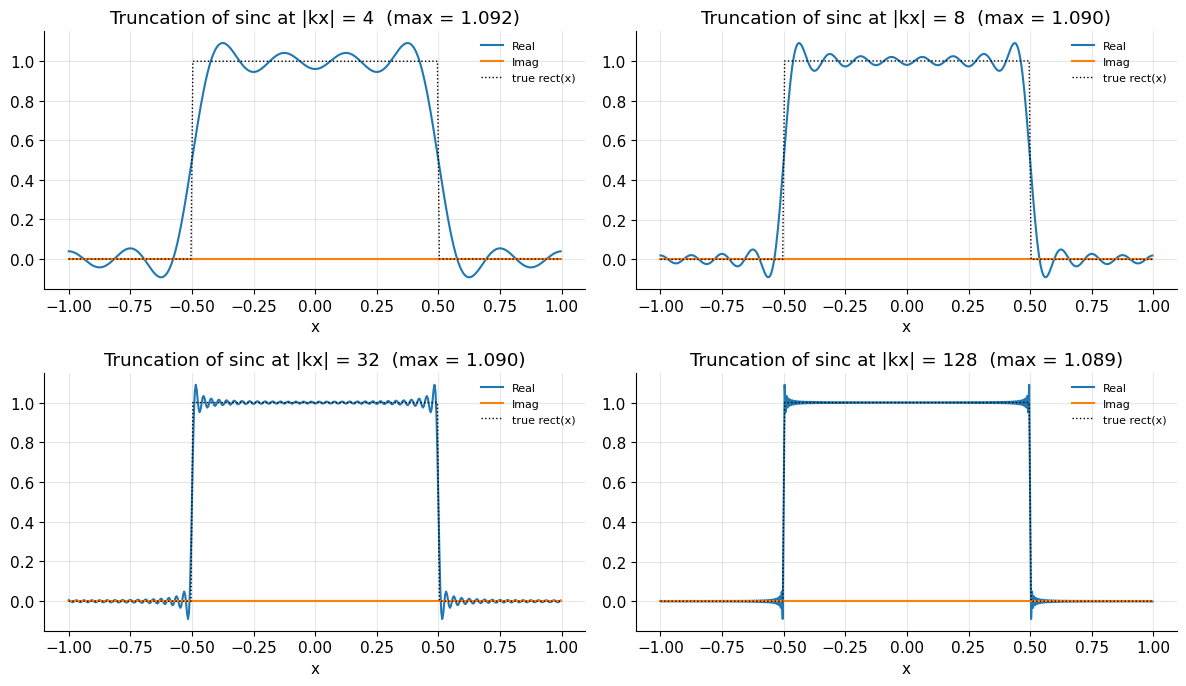

In [4]:
N = 512
kxmax = 128                                          # extent of the full k-space grid (reciprocal units of x)
kx = np.linspace(-N / 2, N / 2 - 1, N) * (2 * kxmax) / N   # k-space grid, spacing dk = 0.5 -> FOV = 1/dk = 2
x = np.linspace(-N / 2, N / 2 - 1, N) / (2 * kxmax)         # image grid, spacing 1/(2 kxmax)
dk = kx[1] - kx[0]

fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for idx, kxmax_truncate in enumerate([4, 8, 32, 128]):
    F = np.sinc(kx)                                  # k-space of rect(x)
    F[np.abs(kx) > kxmax_truncate] = 0               # finite sampling: keep |kx| <= kxmax_truncate
    f = dk * np.sqrt(N) * mt.ifftc(F)                # continuous inverse FT (RM3): scaled so rect has height 1
    ax = axs[idx // 2, idx % 2]
    ax.plot(x, np.real(f), label="Real")
    ax.plot(x, np.imag(f), label="Imag")
    ax.plot(x, mt.rect(x), "k:", lw=1, label="true rect(x)")
    ax.set_title(f"Truncation of sinc at |kx| = {kxmax_truncate}  (max = {np.real(f).max():.3f})")
    ax.set_xlabel("x"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The more k-space is kept, the sharper the edges and the narrower the ripples; the overshoot stays near 1.09. The imaginary part is zero because the truncated k-space is still real and symmetric.

## 9. Point spread function (PSF) analysis → [I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)

PSF analysis characterizes any linear system, including MRI: put in an ideal point object, $\delta(x)$, and observe the output of the system $\mathcal H$:

$$psf(x)=\mathcal H\{\delta(x)\}.$$

In words: the PSF is the image the system makes of a single point.

In MRI it is usually easiest to start in k-space, where the data are sampled and where effects such as finite coverage, $T_2^*$ decay during the readout, or filters act as a **multiplicative weighting**. Because
$\mathcal F\{\delta(x)\}=1$, the k-space of the point's image is just that weighting:

$$PSF(k_x)=\mathcal F\{psf(x)\}.$$

By the convolution theorem, when imaging a real object $f(x)$ the reconstructed image is the object convolved with the PSF:

$$\hat f(x)=\mathcal F^{-1}\{\hat F(k_x)\}=\mathcal F^{-1}\{F(k_x)\,PSF(k_x)\}=f(x)*psf(x).$$

In words: know the k-space weighting → know the blur. The truncation example above is the special case $PSF(k_x)=\mathrm{rect}(k_x/W_{kx})$, $psf(x)=W_{kx}\mathrm{sinc}(W_{kx}x)$.

## 10. The discrete Fourier transform (DFT) → [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)

The DFT is used for Fourier analysis of discretely sampled data. It maps $N$ values $f[n]$, $n=0,1,\dots,N-1$, to $N$ frequency coefficients $F[m]$, $m=0,1,\dots,N-1$:

$$F[m]=\sum_{n=0}^{N-1}f[n]\,e^{-i2\pi mn/N}.$$

In words: correlate the samples with a wave that makes $m$ cycles across the array. It is computed with the **fast Fourier transform** (FFT) algorithm ($\mathcal O(N\log N)$ instead of $\mathcal O(N^2)$).

The formula is very similar to the continuous FT, so most identities and pairs carry over (with shifts becoming circular), and it extends to multiple dimensions in the same way.
The precise link, for centred grids $x_n=(n-N/2)\Delta x$, $k_m=(m-N/2)\Delta k$:

$$F(k_m)\approx\Delta x\sum_nf(x_n)e^{-i2\pi k_mx_n}=\Delta x\cdot\texttt{fftshift(fft(ifftshift(f)))}=\Delta x\sqrt N\cdot\texttt{mt.fftc}(f),\qquad\Delta x\,\Delta k=\frac1N.$$

In words: multiply the FFT by the sample spacing and use `fftshift`/`ifftshift` so that zero position and zero frequency sit in the middle of the arrays; the frequency spacing is one over the sampled length ($FOV=1/\Delta k$), the frequency range one over the sample spacing.

**Where the DFT comes from (sketch).** Start from the continuous FT and include sampling with the impulse train:

1. Sampling $f$ every $\Delta x$, $f(x)\cdot\sum_n\delta(x-n\Delta x)$, makes the spectrum **periodic** with period $1/\Delta x$ (convolution with a comb).
2. Keeping only $N$ samples (a rect of length $N\Delta x$) and treating them as one period of a periodic signal makes the spectrum **discrete**, with spacing $1/(N\Delta x)$.
3. A function that is both periodic and discrete in both domains is fully described by $N$ numbers per domain — and the transform between them is exactly the DFT.

Consequences: the DFT always "sees" periodic copies (aliasing, wrap-around — [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)), and its convolution is circular.

## Key takeaways

- Phase: use atan2 (`np.angle`); multiplication adds phases; MRI precession is $e^{-i\omega t}$ (clockwise).
- ODEs: final + (initial − final)·$e^{-t/T_c}$; rotation via $z=x+iy$; matrix ODE → matrix exponential; steady state where the derivative vanishes.
- MRI Fourier convention: $F(k)=\int f(x)e^{-i2\pi kx}dx$, $k$ in cycles/m, no $2\pi$ prefactors.
- Shift ↔ linear phase, scaling ↔ inverse scaling, convolution ↔ multiplication, real ↔ Hermitian, energy preserved.
- Truncating k-space convolves the image with a sinc: resolution $1/W_{kx}$ and Gibbs ringing; in general the image is object ∗ PSF.
- FFT ≈ continuous FT times $\Delta x$ on centred grids with $\Delta x\Delta k=1/N$; the DFT is periodic in both domains.

## Check your understanding

1. Using the table, what is the FT of $\mathrm{rect}\big((x-a)/W\big)$?
<details><summary>Answer</summary>

Scaling gives $W\,\mathrm{sinc}(Wk_x)$, the shift multiplies by $e^{-i2\pi ak_x}$: $\;W\,\mathrm{sinc}(Wk_x)\,e^{-i2\pi ak_x}$.

</details>

2. In the truncation example, the image grid spacing is $1/(2\cdot128)$ and the k-space spacing is 0.5. What is the FOV, and what would happen to an object wider than it?
<details><summary>Answer</summary>

$FOV=1/\Delta k=2$ (the $x$ axis runs from −1 to 1). A wider object would wrap around (aliasing), because sampled k-space corresponds to a periodic image.

</details>

3. During the readout $T_2^*$ decay weights k-space by $e^{-|t(k_x)|/T_2^*}$. How do you find the resulting blur?
<details><summary>Answer</summary>

That weighting is $PSF(k_x)$; the blur kernel is its inverse FT, $psf(x)=\mathcal F^{-1}\{PSF(k_x)\}$, and the image is $f*psf$ ([I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)).

</details>

4. What is $\int_{-\infty}^{\infty}\cos(x)\,\delta(x-\pi)\,dx$?
<details><summary>Answer</summary>

Sifting property: $\cos(\pi)=-1$.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "MRI Math Concepts".
Changes: added ODE, rotation/cross-product and DFT↔FT sections, symbol table, more functions (tri, Gaussian, jinc) and identities (derivative, Hermitian symmetry, Parseval, rotation, comb spacing, Lorentzian), links to refreshers RM1–RM6;
corrected the phase formula (atan2 instead of tan⁻¹(b/a)), the PSF typo ($\mathcal f\to\mathcal F$), clarified the delta as a distribution, and scaled the truncation example so the reconstructed rect has its true height.*